# Visualização das métricas de kills

Comparação dos resultados salvos nos CSVs desta pasta. As métricas se referem ao conjunto de **validação**; menor MAE e RMSE indicam menor erro. O conjunto de teste não é analisado aqui.

Execute as células em ordem após atualizar os CSVs. Dependências: `pandas` e `matplotlib` (incluídas em `requirements.txt`).

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

arquivos = {
    'baseline': 'baseline_kills.csv',
    'modelos': 'regressao_linear_kills.csv',
    'busca': 'regressao_linear_busca.csv',
    'coeficientes': 'regressao_linear_coeficientes.csv',
}

# Aceita notebooks iniciados na raiz do projeto ou dentro de results/metrics.
candidatos = (
    pasta
    for base in (Path.cwd(), *Path.cwd().parents)
    for pasta in (base, base / 'results' / 'metrics')
)
pasta_metricas = next(
    (pasta for pasta in candidatos if all((pasta / nome).is_file() for nome in arquivos.values())),
    None,
)
if pasta_metricas is None:
    raise FileNotFoundError('CSV não encontrado. Abra o notebook na raiz do projeto ou em results/metrics.')

dados = {chave: pd.read_csv(pasta_metricas / nome) for chave, nome in arquivos.items()}
#display(Markdown(f'**Arquivos lidos de:** `{pasta_metricas}`'))
display(pd.DataFrame({'arquivo': list(arquivos.values()), 'linhas': [len(dados[chave]) for chave in arquivos]}))

,arquivo,linhas
0,baseline_kills.csv,4
1,regressao_linear_kills.csv,2
2,regressao_linear_busca.csv,8
3,regressao_linear_coeficientes.csv,25


## Comparação geral

Todas as linhas abaixo usam as mesmas partidas de validação. R² aparece apenas nos CSVs dos modelos; os baselines não trazem essa métrica.

In [3]:
nomes_baseline = {
    'media': 'Média histórica',
    'media_20': 'Média das últimas 20',
    'minimo': 'Mínimo histórico',
    'maximo': 'Máximo histórico',
}
nomes_modelos = {'regressao_linear': 'Regressão linear', 'ridge': 'Ridge'}

baseline = dados['baseline'].query("conjunto == 'validacao'").copy()
modelos = dados['modelos'].query("conjunto == 'validacao'").copy()
baseline['Método'] = baseline['regra'].map(nomes_baseline).fillna(baseline['regra'])
modelos['Método'] = modelos['modelo'].map(nomes_modelos).fillna(modelos['modelo'])
comparacao = pd.concat(
    [baseline[['Método', 'partidas', 'MAE', 'RMSE']],
     modelos[['Método', 'partidas', 'MAE', 'RMSE', 'R2']]],
    ignore_index=True,
).sort_values('MAE').reset_index(drop=True)
if comparacao['partidas'].nunique() != 1:
    raise ValueError('Os métodos usam números diferentes de partidas; confira os conjuntos antes de comparar.')
display(comparacao.round({'MAE': 3, 'RMSE': 3, 'R2': 3}))

referencia = baseline.loc[baseline['regra'].eq('media'), 'MAE'].iloc[0]
mae_linear = modelos.loc[modelos['modelo'].eq('regressao_linear'), 'MAE'].iloc[0]
display(Markdown(
    f'**Regressão linear vs. média histórica:** MAE {mae_linear:.3f} vs. {referencia:.3f} '
    f'({referencia - mae_linear:.3f} kill a menos por partida, em média; '
    f'{(referencia - mae_linear) / referencia:.1%} de redução).'
))

,Método,partidas,MAE,RMSE,R2
0,Regressão linear,25916,5.362,6.925,0.159
1,Ridge,25916,5.362,6.925,0.159
2,Média histórica,25916,5.411,6.974,NaN
3,Média das últimas 20,25916,5.464,7.040,NaN
4,Mínimo histórico,25916,15.514,17.333,NaN
5,Máximo histórico,25916,21.097,23.285,NaN


**Regressão linear vs. média histórica:** MAE 5.362 vs. 5.411 (0.049 kill a menos por partida, em média; 0.9% de redução).

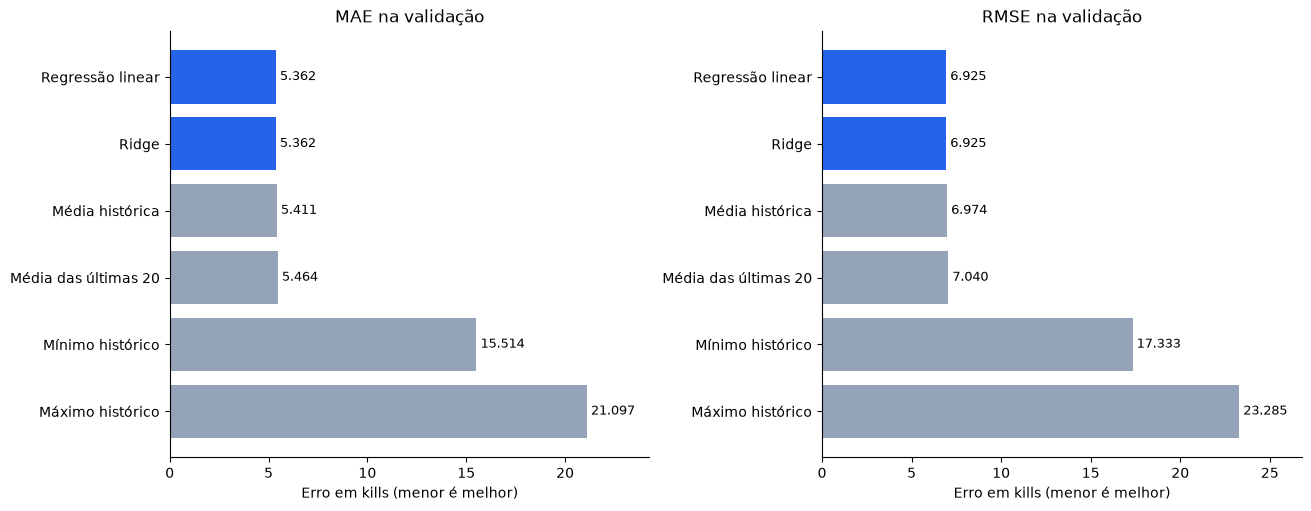

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
cores = ['#2563eb' if metodo in nomes_modelos.values() else '#94a3b8' for metodo in comparacao['Método']]
for eixo, metrica in zip(eixos, ['MAE', 'RMSE']):
    barras = eixo.barh(comparacao['Método'], comparacao[metrica], color=cores)
    eixo.invert_yaxis()
    eixo.set_title(f'{metrica} na validação')
    eixo.set_xlabel('Erro em kills (menor é melhor)')
    eixo.set_xlim(0, comparacao[metrica].max() * 1.15)
    eixo.bar_label(barras, fmt='%.3f', padding=3, fontsize=9)
    eixo.spines[['top', 'right']].set_visible(False)
plt.show()

## Busca de `alpha` para Ridge

A regressão linear sem regularização (`alpha = 0`) serve de referência. O gráfico amplia a escala vertical para mostrar diferenças pequenas de MAE.

,Configuração,MAE_treino,MAE_validacao,RMSE_validacao,R2_validacao
0,Linear,5.313331,5.362004,6.924526,0.159004
1,Ridge 0.01,5.313331,5.362004,6.924526,0.159004
2,Ridge 0.1,5.313331,5.362006,6.924527,0.159003
3,Ridge 1,5.313330,5.362024,6.924539,0.159000
4,Ridge 10,5.313331,5.362171,6.924643,0.158975
5,Ridge 100,5.313479,5.362684,6.925011,0.158886
6,Ridge 1000,5.314268,5.363300,6.925517,0.158763
7,Ridge 10000,5.316015,5.365787,6.927375,0.158311


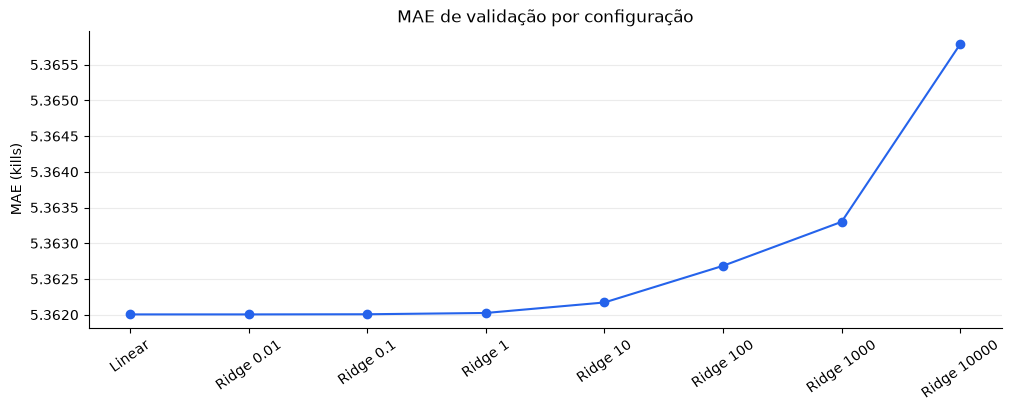

In [5]:
busca = dados['busca'].sort_values('alfa').copy()
busca['Configuração'] = busca.apply(
    lambda linha: 'Linear' if linha['modelo'] == 'regressao_linear' else f"Ridge {linha['alfa']:g}",
    axis=1,
)
display(busca[['Configuração', 'MAE_treino', 'MAE_validacao', 'RMSE_validacao', 'R2_validacao']])

fig, eixo = plt.subplots(figsize=(10, 4), layout='constrained')
eixo.plot(busca['Configuração'], busca['MAE_validacao'], marker='o', color='#2563eb')
eixo.set_title('MAE de validação por configuração')
eixo.set_ylabel('MAE (kills)')
eixo.tick_params(axis='x', rotation=35)
eixo.grid(axis='y', alpha=0.25)
eixo.spines[['top', 'right']].set_visible(False)
plt.show()